# Gold Standard Creation - OurAirports x Kaggle

Builds a labeled set of record pairs between **OurAirports** (`id1`, left) and **Kaggle** (`id2`, right) to train and evaluate the identity-resolution matchers for this dataset pair. Same method as the Wikidata x OurAirports gold standard, adapted to Kaggle.

Output: `data/identity_resolution/gold_standard/gold_standard_oa_kg.csv`.

In [1]:
import pandas as pd
import random
import math
import matplotlib.pyplot as plt
from pathlib import Path
from PyDI.io import load_csv

from PyDI.entitymatching import TokenBlocker, RuleBasedMatcher, BaseComparator, StringComparator
from collections import Counter
import h3

from sklearn.model_selection import StratifiedKFold

/Users/I569494/Development/Uni Mannheim/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Workflow

1. **Load data** (OurAirports, Kaggle) and set the random seed.
2. **Positive cases**
   - Pairs with the same valid ICAO code. Merge both sources on `icao` and score every pair with the weighted similarity (`name`, `geo_distance`, `city`). Remove pairs that are very likely not the same airport despite the same ICAO: distance > 50 km, or both IATA codes present and different.
     - Hard positives: the 250 lowest-scoring pairs of the cleaned set.
     - Normal positives: 250 pairs drawn at random from the remaining cleaned pairs.
   - Code-changed positives: pairs with a **different** ICAO but the **same** IATA code (and within 50 km). The airport most likely changed its ICAO code, so these are matches that the ICAO merge cannot find. They are added as a separate group.
3. **Negative cases** (pairs with different valid ICAO codes)
   - Blocking (Rule A: `countryCode` + distinguishing `name` token, Rule B: H3 grid), union and de-duplication give the candidate pairs.
   - Keep only candidates with a valid ICAO on both sides that differs, and score them with the same weighted similarity.
   - Pairs with the same IATA code leave the pool (see code-changed positives). Pairs less than 3 km apart and pairs with identical names less than 10 km apart are dropped, because they are likely the same airport.
   - Hard negatives: 125 pairs with the most similar `name` plus 125 pairs that are closest to each other (at least 3 km apart).
   - Normal negatives: 250 pairs drawn at random from the remaining pool.
4. **Checks**: no pair appears in more than one group; manual inspection of hard positives and hard negatives.
5. **Split and save**: stratified by group type into test (30 %) and train/validation (70 %), with 5 stratified folds on the train/validation part. Everything is written to one CSV with `split` and `fold` columns.

**Kaggle-specific note:** 319 Kaggle records store missing coordinates as `(0.0, 0.0)` rather than null. These are converted to `NaN` before any distance is computed, so a real airport is never wrongly dropped for being "thousands of km away" from a `(0, 0)` record.

In [2]:
DATA_DIR = Path("../../../data/normalized_outputs")
OUTPUT_DIR = Path("../../../data/identity_resolution/gold_standard")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

OURAIRPORT_FILE = DATA_DIR / "ourairportsNormalized.csv"
KAGGLE_FILE = DATA_DIR / "kaggleNormalized.csv"

df_oa = load_csv(OURAIRPORT_FILE, name="ourairports")
df_oa.attrs['source'] = 'ourairports'

df_kg = load_csv(KAGGLE_FILE, name="kaggle")
df_kg.attrs['source'] = 'kaggle'

# Kaggle stores missing coordinates as (0, 0); make them NaN so distances are correct
zero_coord = (df_kg["lat"] == 0.0) & (df_kg["lon"] == 0.0)
df_kg.loc[zero_coord, ["lat", "lon"]] = pd.NA
print(f"Kaggle: set {int(zero_coord.sum())} (0,0) coordinates to NaN")

print("===================================== \nOurAirports\n===================================== ")
print(f"Loaded {len(df_oa)} records")
print(f"Columns: {list(df_oa.columns)}")
display(df_oa.head(3))

print("===================================== \nKaggle\n===================================== ")
print(f"Loaded {len(df_kg)} records")
print(f"Columns: {list(df_kg.columns)}")
display(df_kg.head(3))

Kaggle: set 319 (0,0) coordinates to NaN
OurAirports
Loaded 86151 records
Columns: ['id', 'name', 'type', 'scheduledService', 'localCode', 'lat', 'lon', 'elevation', 'countryCode', 'isoRegion', 'city', 'runway_lengthFt', 'runway_widthFt', 'runway_surface', 'runway_lighted', 'runway_closed', 'runway_leIdent', 'runway_heIdent', 'wikipedia', 'continent', 'iata', 'icao', 'countryName']


,id,name,type,scheduledService,localCode,lat,lon,elevation,countryCode,isoRegion,...,runway_surface,runway_lighted,runway_closed,runway_leIdent,runway_heIdent,wikipedia,continent,iata,icao,countryName
0,oa_1,total rf heliport,heliport,False,00A,40.070985,-74.933689,3.3528,US,US-PA,...,ASPH-G,false,false,H1,NaN,NaN,NaN,NaN,NaN,united states
1,oa_2,aero b ranch airport,small_airport,False,00AA,38.704022,-101.473911,1046.9880,US,US-KS,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,united states
2,oa_3,lowell field,small_airport,False,00AK,59.947733,-151.692524,137.1600,US,US-AK,...,GRVL,false,false,N,S,NaN,NaN,NaN,NaN,united states


Kaggle
Loaded 6391 records
Columns: ['id', 'name', 'iata', 'icao', 'lat', 'lon', 'countryCode', 'countryCodeA3', 'countryName', 'city', 'cityIata', 'timezone']


,id,name,iata,icao,lat,lon,countryCode,countryCodeA3,countryName,city,cityIata,timezone
0,kg_1,pilanesberg international,NTY,FAPN,-25.333822,27.173358,ZA,ZAF,south africa,sun city,NTY,Africa/Johannesburg
1,kg_2,clovis municipal,CVN,KCVN,34.425139,-103.079278,US,USA,united states of america,clovis new mexico,CVN,America/Denver
2,kg_3,cannon air force base,CVS,KCVS,34.382775,-103.322147,US,USA,united states of america,clovis new mexico,CVN,America/Denver


### Set random seed

In [3]:
SEED = 1234
random.seed(SEED)

## Positive Pairs (Matches)

### Clean Data and Merge with ICAO

In [4]:
valid_icao = r"^[A-Z0-9]{4}$"

oa_valid = df_oa[df_oa["icao"].astype(str).str.match(valid_icao, na=False)]
kg_valid = df_kg[df_kg["icao"].astype(str).str.match(valid_icao, na=False)]

true_pairs = pd.merge(
    oa_valid,
    kg_valid,
    on="icao",
    how="inner",
    suffixes=("_oa", "_kg"),
)

display(true_pairs.head(3))

candidates_true = true_pairs.rename(columns={"id_oa": "id1", "id_kg": "id2"})
print(f"ICAO-merge positive pool: {len(candidates_true)} pairs")

,id_oa,name_oa,type,scheduledService,localCode,lat_oa,lon_oa,elevation,countryCode_oa,isoRegion,...,name_kg,iata_kg,lat_kg,lon_kg,countryCode_kg,countryCodeA3,countryName_kg,city_kg,cityIata,timezone
0,oa_9094,chuathbaluk airport,small_airport,True,9A3,61.579102,-159.216003,74.3712,US,US-AK,...,chuathbaluk airport,CHU,61.579167,-159.215556,US,USA,united states of america,chuathbaluk alaska,CHU,America/Anchorage
1,oa_9883,afutara aerodrome,small_airport,False,NaN,-9.191389,160.948611,7.0104,SB,SB-ML,...,afutara airport,AFT,-9.183056,160.949722,SB,SLB,solomon islands,afutara,AFT,Pacific/Guadalcanal
2,oa_9884,ulawa airport,small_airport,False,NaN,-9.860544,161.979547,12.1920,SB,SB-MK,...,ulawa airport,RNA,-9.854722,161.979167,SB,SLB,solomon islands,arona,RNA,Pacific/Guadalcanal


ICAO-merge positive pool: 4700 pairs


### Run comparators to get the weighted similarity score

#### Define and instantiate comparators

In [5]:
# name: tolerant of small spelling differences
name_comp = StringComparator(column="name", similarity_function="jaro_winkler")

# city: same metric, weighted lower later (Kaggle city often contains "city state")
city_comp = StringComparator(column="city", similarity_function="jaro_winkler")

# lat/lon: great-circle (Haversine) distance between the two points, converted to similarity
class GeoDistanceComparator(BaseComparator):
    """Great-circle (Haversine) distance between two lat/lon points, converted to similarity."""

    def __init__(self, lat_column="lat", lon_column="lon", max_distance_km=10.0):
        super().__init__(name="geo_distance")
        self.lat_column = lat_column
        self.lon_column = lon_column
        self.max_distance_km = max_distance_km

    def compare(self, record1, record2):
        lat1, lon1 = record1.get(self.lat_column), record1.get(self.lon_column)
        lat2, lon2 = record2.get(self.lat_column), record2.get(self.lon_column)
        if pd.isna(lat1) or pd.isna(lon1) or pd.isna(lat2) or pd.isna(lon2):
            return 0.5  # neutral: can't compute without both coordinates
        distance_km = self._haversine_km(lat1, lon1, lat2, lon2)
        return max(0.0, 1.0 - distance_km / self.max_distance_km)

    @staticmethod
    def _haversine_km(lat1, lon1, lat2, lon2):
        R = 6371.0  # Earth radius in km
        phi1, phi2 = math.radians(lat1), math.radians(lat2)
        dphi = math.radians(lat2 - lat1)
        dlambda = math.radians(lon2 - lon1)
        a = math.sin(dphi / 2) ** 2 + math.cos(phi1) * math.cos(phi2) * math.sin(dlambda / 2) ** 2
        return 2 * R * math.asin(math.sqrt(a))

geo_comp = GeoDistanceComparator(max_distance_km=2.0)

# Quick sanity check: compare the first candidate pair field by field
comparators = [name_comp, geo_comp, city_comp]
comparator_names = ["name", "geo_distance", "city"]

row = candidates_true.iloc[0]
r1 = df_oa.set_index("id").loc[row["id1"]]
r2 = df_kg.set_index("id").loc[row["id2"]]
for cname, comp in zip(comparator_names, comparators):
    print(f"  {cname:<12} -> {comp.compare(r1, r2):.2f}")

  name         -> 1.00
  geo_distance -> 0.99
  city         -> 0.92


### Score candidates with `RuleBasedMatcher`

Goal: combine the per-attribute scores into one similarity score per candidate pair. The score is used only to rank pairs when selecting the hard cases (lowest-scoring positives, highest-scoring negatives).

Method: weighted sum of three comparator scores. The weights sum to 1.0, so the final score lies in [0, 1].

| Attribute | Weight | Rationale |
|---|---|---|
| `name` | 0.50 | Most discriminative attribute available for almost every record |
| `geo_distance` | 0.35 | The same airport has (nearly) the same coordinates in every source (`max_distance_km=2.0`) |
| `city` | 0.15 | Lowest: Kaggle's city field often contains `"city state"` rather than a bare city name |

`icao` and `iata` are left out. The labels are derived from `icao` (pairs with the same ICAO are positives, pairs with different ICAO are negatives), so using it as a feature would leak the label into the score and make the hardness ranking meaningless.

`threshold=0.0` keeps every candidate pair, because the scores are used for ranking and no cutoff is applied here.

- Scored 4700 candidate pairs


,id1,id2,score,notes
0,oa_9094,kg_4470,0.984005,comparators=3
1,oa_9883,kg_2886,0.706680,comparators=3
2,oa_9884,kg_2154,0.886484,comparators=3
3,oa_9885,kg_5381,0.999962,comparators=3
4,oa_9887,kg_4301,0.575503,comparators=3


count    4700.000000
mean        0.876191
std         0.121408
min         0.150000
25%         0.821879
50%         0.921992
75%         0.957303
max         1.000000
Name: score, dtype: float64

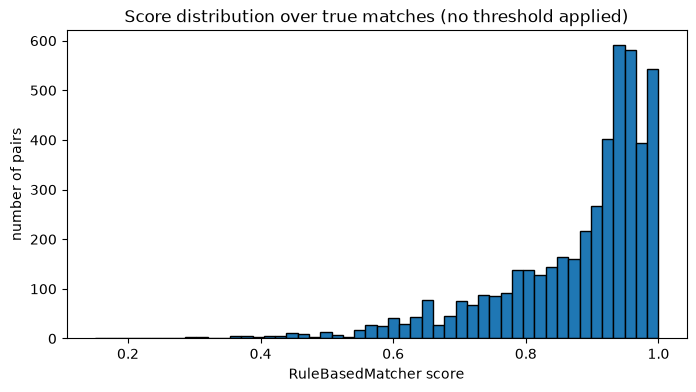

In [6]:
weights = [
    0.5,      # name
    0.35,     # geo_distance
    0.15      # city
]

matcher = RuleBasedMatcher()
correspondences, debug_results = matcher.match(
    df_left = df_oa,
    df_right = df_kg,
    candidates = candidates_true,
    id_column = "id",
    comparators = comparators,
    weights = weights,
    threshold = 0.0,  # keep everything for now
    debug = True,
)

print(f"- Scored {len(correspondences)} candidate pairs")
display(correspondences.head(5))

display(correspondences["score"].describe())

# visualization
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(correspondences["score"], bins = 50, edgecolor= "black")
ax.set_xlabel("RuleBasedMatcher score")
ax.set_ylabel("number of pairs")
ax.set_title("Score distribution over true matches (no threshold applied)")
plt.show()

### Generate the hard positives
Goal: pick the 250 positive pairs that are hardest to recognize as matches, i.e. pairs that are the same airport but look the least similar.

Method:
1. The true matches are the pairs with the same ICAO code (see above). Each pair already has a weighted similarity score from the `RuleBasedMatcher` (`name`, `geo_distance`, `city`).
2. ICAO codes in the sources are not always correct. A pair with a wrong ICAO is not a real match, and because it is dissimilar by construction, it would end up at the very bottom of the ranking. Before sorting we therefore remove pairs that are very likely not the same airport:
   - the two records are more than 50 km apart, or
   - both records have an IATA code and the codes differ.
   Pairs without coordinates (including the Kaggle `(0, 0)` records) are kept in the pool, since the distance cannot be checked, but they are excluded from the hard negatives and can only appear among the normal positives.
3. The remaining pairs are sorted by score in ascending order and the first 250 are taken as **hard positives**.
4. The **normal positives** are 250 pairs drawn at random from the remaining cleaned pairs (without the hard positives), using a fixed random seed.

In [7]:
attrs_oa = df_oa.set_index("id")[["lat", "lon", "iata"]].add_suffix("_oa")
attrs_kg = df_kg.set_index("id")[["lat", "lon", "iata"]].add_suffix("_kg")

pos = (
    correspondences
        .join(attrs_oa, on="id1")
        .join(attrs_kg, on="id2")
)

coords = ["lat_oa", "lon_oa", "lat_kg", "lon_kg"]
pos[coords] = pos[coords].apply(pd.to_numeric, errors="coerce")

pos["dist_km"] = [
    GeoDistanceComparator._haversine_km(a, b, c, d)
    if pd.notna(a) and pd.notna(b) and pd.notna(c) and pd.notna(d) else float("nan")
    for a, b, c, d in zip(pos["lat_oa"], pos["lon_oa"], pos["lat_kg"], pos["lon_kg"])
]

iata_conflict = (
    pos["iata_oa"].notna() & pos["iata_kg"].notna() & (pos["iata_oa"] != pos["iata_kg"])
)

# Remove (too distant, distance > 50 km) OR (different IATA) pairs.
# NaN distance (missing or (0,0) coords) is kept in the pool.
clean = pos[(pos["dist_km"].fillna(0) <= 50) & ~iata_conflict]
print(f"removed {len(pos) - len(clean)} suspicious positives")

# sort and get the head 250
hard_positives = (
    clean
        .sort_values("score", ascending=True)
        .head(250)
        .drop(columns=["notes"], errors="ignore")
        .copy()
)
hard_positives["type"] = "hard positive"
hard_positives["label"] = 1

removed 83 suspicious positives


### Manual check of the hard positives

Goal: verify by eye that the cleaned hard positives are really the same airport, and see what kind of "hard" they are.

Method: print the pairs side by side (name, city, country, ICAO, IATA, coordinates, distance) for the three lowest-scoring pairs and a random one from the rest.

In [8]:
SHOW_COLS = ["name", "city", "countryCode", "icao", "iata", "lat", "lon"]

def inspect_pairs(pairs, df_left, df_right, n=20, random_n=0, seed=SEED):
    cols_l = [c for c in SHOW_COLS if c in df_left.columns]
    cols_r = [c for c in SHOW_COLS if c in df_right.columns]
    shared = [c for c in cols_l if c in cols_r]

    left = df_left.set_index("id")[cols_l].add_suffix("_oa")
    right = df_right.set_index("id")[cols_r].add_suffix("_kg")

    view = (
        pairs[["id1", "id2", "score"]]
            .reset_index(drop=True)
            .join(left, on="id1")
            .join(right, on="id2")
    )
    coords = ["lat_oa", "lon_oa", "lat_kg", "lon_kg"]
    view[coords] = view[coords].apply(pd.to_numeric, errors="coerce")
    view["dist_km"] = [
        GeoDistanceComparator._haversine_km(a, b, c, d)
        if pd.notna(a) and pd.notna(b) and pd.notna(c) and pd.notna(d) else float("nan")
        for a, b, c, d in zip(view["lat_oa"], view["lon_oa"], view["lat_kg"], view["lon_kg"])
    ]

    shown = view.head(n)
    if random_n:
        shown = pd.concat([shown, view.iloc[n:].sample(min(random_n, len(view) - n), random_state=seed)])

    for _, r in shown.iterrows():
        print(f"score={r['score']:.3f}  dist={r['dist_km']:.1f} km  ({r['id1']} <-> {r['id2']})")
        for c in shared:
            print(f"  {c:12s} OA: {str(r[c + '_oa']):40s} KG: {r[c + '_kg']}")
        print()

inspect_pairs(hard_positives.sort_values("score"), df_oa, df_kg, n = 3, random_n = 1)

score=0.150  dist=17.0 km  (oa_67228 <-> kg_4957)
  name         OA: tura mountain airport                    KG: nan
  city         OA: tura                                     KG: tura
  countryCode  OA: RU                                       KG: RU
  icao         OA: UNIT                                     KG: UNIT
  iata         OA: GOY                                      KG: GOY
  lat          OA: 64.333511                                KG: 64.2
  lon          OA: 100.432892                               KG: 100.26

score=0.302  dist=1.1 km  (oa_80898 <-> kg_5253)
  name         OA: rajkot international airport             KG: nan
  city         OA: rajkot                                   KG: rajkot
  countryCode  OA: IN                                       KG: IN
  icao         OA: VAHS                                     KG: VAHS
  iata         OA: HSR                                      KG: HSR
  lat          OA: 22.378824                                KG: 22.3869175
 

### Generate the normal positives
The **normal positives** are 250 pairs drawn at random from the remaining cleaned pairs (without the hard positives), using a fixed random seed.

In [9]:
normal_positives = (
    clean.drop(hard_positives.index)
         .sample(250, random_state = SEED)
         .drop(columns = ["notes"], errors = "ignore")
         .copy()
)
normal_positives["type"] = "normal positive"
normal_positives["label"] = 1

## Negative Pairs (Non-Matches)

### Blocking
Use blocking to find candidate pairs with different ICAO.
We use two blocking rules and concatenate the results:
- Blocking Rule A: `countryCode` + distinguishing `name` tokens
- Blocking Rule B: geographic grid (H3)

#### Rule A
- Goal: generate candidate pairs between OurAirports and Kaggle. Generic words in `name` (`airport`, `international`, common geographic words, ...) must not be used as blocking keys, because they would put thousands of unrelated records into the same block.

- Method: `TokenBlocker` on `name`.
  - A token is treated as non-distinguishing if it would create too many candidate pairs. The number of pairs a token creates is the number of OurAirports names containing it times the number of Kaggle names containing it, which is exactly the size of the block that token would produce. Tokens above `MAX_PAIRS_PER_TOKEN` are excluded. This list is derived from the data, not hand-picked.
  - `countryCode` is prepended to each remaining token (e.g. `"US_scammon"`), so a pair is a candidate only if the two records share a distinguishing token **and** have the same country.

- Limitation: records whose name has no distinguishing token left, or that have no `countryCode`, produce no tokens and cannot be found by this rule. Pairs whose `countryCode` differs between the two sources are also missed. Both are covered by Rule B (geographic grid).

In [10]:
MAX_PAIRS_PER_TOKEN = 2000   # trade-off between block size and recall; tune with the debug CSV

def name_tokens(name):
    if not isinstance(name, str):
        return set()
    return {t for t in name.split() if len(t) >= 2}

doc_freq_oa = Counter(t for n in df_oa["name"] for t in name_tokens(n))
doc_freq_kg = Counter(t for n in df_kg["name"] for t in name_tokens(n))

COMMON_TOKENS = {
    t for t, c in doc_freq_oa.items()
    if c * doc_freq_kg.get(t, 0) > MAX_PAIRS_PER_TOKEN
}
print(f"Excluding {len(COMMON_TOKENS)} tokens that would each create more than "
      f"{MAX_PAIRS_PER_TOKEN} candidate pairs")

# The tokenizer only sees one column, so country and name are packed into one string.
def add_name_with_country(d):
    d = d.copy()
    d["name_with_country"] = d["countryCode"].fillna("") + "|" + d["name"].fillna("")
    return d

oa_blk = add_name_with_country(df_oa)
kg_blk = add_name_with_country(df_kg)

def country_scoped_tokenizer(text):
    if not isinstance(text, str) or "|" not in text:
        return []
    country, name = text.split("|", 1)
    if not country:          # Rule A needs a country code
        return []
    return [f"{country}_{t}" for t in name.split()
            if len(t) >= 2 and t not in COMMON_TOKENS]

blocker_token = TokenBlocker(
    df_left=oa_blk,
    df_right=kg_blk,
    column="name_with_country",
    id_column="id",
    tokenizer=country_scoped_tokenizer,
)

candidates_token = blocker_token.materialize()
print(f"Rule A candidate pairs: {len(candidates_token):,}")

def unreachable_by_rule_a(d):
    return d["name_with_country"].apply(lambda x: len(country_scoped_tokenizer(x)) == 0)

for label, d in [("OurAirports", oa_blk), ("Kaggle", kg_blk)]:
    m = unreachable_by_rule_a(d)
    print(f"{label}: {m.sum()} records ({m.mean():.1%}) not reachable by Rule A")

Excluding 53 tokens that would each create more than 2000 candidate pairs


Rule A candidate pairs: 41,420
OurAirports: 547 records (0.6%) not reachable by Rule A
Kaggle: 64 records (1.0%) not reachable by Rule A


#### Rule B

- Goal: find candidate pairs that Rule A cannot reach, i.e. records whose names are generic or share no distinguishing token, or whose `countryCode` is missing. Any two records that lie close to each other become candidates, regardless of names or country labels.

- Method: map each record to an [H3](https://h3geo.org/) hexagonal cell at resolution `RESOLUTION` (average edge length ≈ `0.17` km) and use `TokenBlocker` on the H3 cell IDs.
  - Each record emits **7 tokens**: the cell containing it plus its 6 neighboring cells (`h3.grid_disk(cell, 1)`), so pairs split by a cell border are not lost.
  - `countryCode` is deliberately **not** part of the token, so records with a missing or inconsistent `countryCode` are also covered.
  - Records without coordinates (including the Kaggle `(0, 0)` records, already set to `NaN`) emit no tokens and cannot be reached by this rule.

- Candidates of Rule A and Rule B are combined by union and de-duplicated, so a pair only needs to be found by one of the two rules.

In [11]:
RESOLUTION = 9

def geo_h3_tokens(row):
    if pd.isna(row["lat"]) or pd.isna(row["lon"]):
        return []
    center = h3.latlng_to_cell(row["lat"], row["lon"], RESOLUTION)
    return list(h3.grid_disk(center, 1))

print("Test the behavior. Input: (25.0215, 121.5637)")
print(set(geo_h3_tokens({"lat": 25.0215, "lon": 121.5637})))

oa_geo = df_oa.copy()
kg_geo = df_kg.copy()

oa_geo["geo_grid_tokens"] = oa_geo.apply(geo_h3_tokens, axis=1)
kg_geo["geo_grid_tokens"] = kg_geo.apply(geo_h3_tokens, axis=1)

# one lookup for both sources (ids are prefixed, so they cannot collide)
grid_token_lookup = {
    **oa_geo.set_index("id")["geo_grid_tokens"].to_dict(),
    **kg_geo.set_index("id")["geo_grid_tokens"].to_dict(),
}

def grid_tokenizer(record_id):
    return grid_token_lookup.get(record_id, [])

# TokenBlocker only sees one column, so the id itself is the "text" to tokenize
oa_geo["id_as_text"] = oa_geo["id"]
kg_geo["id_as_text"] = kg_geo["id"]

blocker_geo = TokenBlocker(
    df_left=oa_geo,
    df_right=kg_geo,
    column="id_as_text",
    id_column="id",
    tokenizer=grid_tokenizer,
    min_token_len=1,
)

candidates_geo = blocker_geo.materialize()
print(f"Rule B candidate pairs: {len(candidates_geo):,}")

Test the behavior. Input: (25.0215, 121.5637)
{'894ba0a4ad3ffff', '894ba0a4ac7ffff', '894ba0a4a9bffff', '894ba0a4a8bffff', '894ba0a4e6fffff', '894ba0a4ac3ffff', '894ba0a4ad7ffff'}


Rule B candidate pairs: 5,378


#### Concatenate and Deduplicate

In [12]:
candidates = pd.concat([candidates_geo[["id1", "id2"]], candidates_token[["id1", "id2"]]], axis=0)
candidates = candidates.drop_duplicates(subset=["id1", "id2"]).reset_index(drop=True)

print(f"All candidate pairs after deduplication: {len(candidates)}")
print(candidates["id1"].str[:3].value_counts().to_dict(), candidates["id2"].str[:3].value_counts().to_dict())

All candidate pairs after deduplication: 42240
{'oa_': 42240} {'kg_': 42240}


### Hard Negatives

Goal: pick the 250 negative pairs that are most easily mistaken for a match, i.e. pairs that are different airports but look very similar.

Method:
1. Start from the blocked candidate pairs (Rule A and Rule B). Blocking already removes the obviously unrelated pairs, so the pool resembles what a matcher will actually see.
2. Keep only pairs with a valid ICAO code on **both** sides that **differs**. A pair is a known negative only under the assumption that an ICAO code identifies exactly one airport. Pairs with a missing or invalid ICAO on either side are dropped, because they cannot be labeled either way.
3. ICAO codes are not always stable: the same airport can appear under an old and a new code in different sources. Such pairs are really matches. We handle the likely cases as follows:
   - **Same IATA code** (both present and equal): treated as a match with a changed ICAO code. If the records are within 50 km, they become the group of **code-changed positives**; otherwise they are dropped.
   - **Less than 3 km apart**, or **identical names less than 10 km apart**: likely the same airport, but not certain enough to label. These pairs are dropped.
   Pairs without coordinates are kept, since the distance cannot be checked.
4. The remaining pairs are scored with the same weighted similarity as the positives. Two groups of 125 are selected as the **hard negatives**:
   - the most similar names (airports with the same name in different places), and
   - the closest pairs (at least 3 km apart), which are mostly neighboring airports with different names.

Limitation: the negatives are assumed, not verified by hand. The IATA, distance and name filters and the manual check below reduce this noise but cannot remove it entirely.

In [13]:
attrs_oa = df_oa.set_index("id")[["name", "icao", "iata", "lat", "lon"]].add_suffix("_oa")
attrs_kg = df_kg.set_index("id")[["name", "icao", "iata", "lat", "lon"]].add_suffix("_kg")

pairs = candidates[["id1", "id2"]].join(attrs_oa, on="id1").join(attrs_kg, on="id2")

# keep only pairs with a valid ICAO on both sides, then only different ICAOs (= assumed negatives)
valid_oa = pairs["icao_oa"].astype(str).str.match(valid_icao, na=False)
valid_kg = pairs["icao_kg"].astype(str).str.match(valid_icao, na=False)
known = pairs[valid_oa & valid_kg]
negatives_pool = known[known["icao_oa"] != known["icao_kg"]]

print(f"candidates: {len(pairs):,} | both ICAO valid: {len(known):,} | "
      f"different ICAO: {len(negatives_pool):,}")

# score the pool with the same matcher as the positives
matcher = RuleBasedMatcher()
neg_scores = matcher.match(
    df_left = df_oa,
    df_right = df_kg,
    candidates = negatives_pool[["id1", "id2"]],
    id_column = "id",
    comparators = comparators,
    weights = weights,
    threshold = 0.0,
)
negatives_pool = negatives_pool.merge(neg_scores[["id1", "id2", "score"]], on=["id1", "id2"])

# distance between the two records
coords = ["lat_oa", "lon_oa", "lat_kg", "lon_kg"]
negatives_pool[coords] = negatives_pool[coords].apply(pd.to_numeric, errors="coerce")
negatives_pool["dist_km"] = [
    GeoDistanceComparator._haversine_km(a, b, c, d)
    if pd.notna(a) and pd.notna(b) and pd.notna(c) and pd.notna(d) else float("nan")
    for a, b, c, d in zip(negatives_pool["lat_oa"], negatives_pool["lon_oa"],
                          negatives_pool["lat_kg"], negatives_pool["lon_kg"])
]

# same IATA, different ICAO: the airport most likely changed its ICAO code.
# Within 50 km they become positives; all of them leave the negative pool.
iata_same = (
    negatives_pool["iata_oa"].notna()
    & negatives_pool["iata_kg"].notna()
    & (negatives_pool["iata_oa"] == negatives_pool["iata_kg"])
)
code_changed = negatives_pool[iata_same & (negatives_pool["dist_km"].fillna(0) <= 50)].copy()
code_changed["type"] = "code changed positive"
code_changed["label"] = 1
print(f"{iata_same.sum()} pairs share an IATA code; {len(code_changed)} kept as positives (within 50 km)")
negatives_pool = negatives_pool[~iata_same]

# too close pairs: likely the same airport, but not certain enough to label -> dropped
MIN_NEG_DIST_KM = 3
too_close = negatives_pool["dist_km"] < MIN_NEG_DIST_KM
print(f"removed {too_close.sum()} negatives closer than {MIN_NEG_DIST_KM} km")
negatives_pool = negatives_pool[~too_close]

# identical name and close: likely the same airport -> dropped
same_name_close = (
    (negatives_pool["name_oa"] == negatives_pool["name_kg"])
    & (negatives_pool["dist_km"] < 10)
)
print(f"removed {same_name_close.sum()} negatives with identical names closer than 10 km")
negatives_pool = negatives_pool[~same_name_close].copy()

# name similarity per pair (same comparator as in the score)
names_oa = df_oa.set_index("id")["name"]
names_kg = df_kg.set_index("id")["name"]
negatives_pool["name_sim"] = [
    name_comp.compare(pd.Series({"name": names_oa[a]}), pd.Series({"name": names_kg[b]}))
    for a, b in zip(negatives_pool["id1"], negatives_pool["id2"])
]

# hard negatives need a known distance, since the distance filters cannot be applied otherwise
verifiable = negatives_pool["dist_km"].notna()
print(f"{(~verifiable).sum()} pairs without coordinates are excluded from the hard negatives")

by_name = (
    negatives_pool[verifiable]
        .sort_values(["name_sim", "dist_km"], ascending=[False, True])
        .head(125)
)
by_dist = (
    negatives_pool[verifiable].drop(by_name.index)
        .sort_values(["dist_km", "name_sim"], ascending=[True, False])
        .head(125)
)

hard_negatives = pd.concat([by_name, by_dist]).copy()
hard_negatives["type"] = "hard negative"
hard_negatives["label"] = 0

print(f"negative pool: {len(negatives_pool):,}")
print(f"name-based: name_sim >= {by_name['name_sim'].min():.2f}, dist {by_name['dist_km'].min():.1f}-{by_name['dist_km'].max():.0f} km")
print(f"distance-based: dist {by_dist['dist_km'].min():.1f}-{by_dist['dist_km'].max():.1f} km, name_sim {by_dist['name_sim'].min():.2f}-{by_dist['name_sim'].max():.2f}")

hard_negatives.head(3)

candidates: 42,240 | both ICAO valid: 8,092 | different ICAO: 3,479


148 pairs share an IATA code; 146 kept as positives (within 50 km)
removed 26 negatives closer than 3 km
removed 0 negatives with identical names closer than 10 km
0 pairs without coordinates are excluded from the hard negatives
negative pool: 3,305
name-based: name_sim >= 0.89, dist 4.9-7770 km
distance-based: dist 3.1-21.5 km, name_sim 0.46-0.89


,id1,id2,name_oa,icao_oa,iata_oa,lat_oa,lon_oa,name_kg,icao_kg,iata_kg,lat_kg,lon_kg,score,dist_km,name_sim,type,label
2717,oa_39238,kg_2749,capital city airport,KCXY,HAR,40.217098,-76.851501,capital city airport,KFFT,FFT,38.181972,-84.906139,0.568611,729.709903,1.0,hard negative,0
586,oa_40065,kg_5320,pope field,KGFD,GFD,39.790715,-85.735019,pope field,KPOB,POB,35.170883,-79.014472,0.565500,784.145228,1.0,hard negative,0
353,oa_42736,kg_2857,smith field,KSLG,SLG,36.191898,-94.489998,smith field,KSMD,SMD,41.143353,-85.152778,0.567088,979.042288,1.0,hard negative,0


#### Manually check

In [14]:
inspect_pairs(hard_negatives, df_oa, df_kg, n = 3, random_n = 1)
inspect_pairs(by_dist.sort_values("name_sim", ascending = False), df_oa, df_kg, n=2)

score=0.569  dist=729.7 km  (oa_39238 <-> kg_2749)
  name         OA: capital city airport                     KG: capital city airport
  city         OA: harrisburg                               KG: frankfort kentucky
  countryCode  OA: US                                       KG: US
  icao         OA: KCXY                                     KG: KFFT
  iata         OA: HAR                                      KG: FFT
  lat          OA: 40.21709824                              KG: 38.1819722
  lon          OA: -76.85150146                             KG: -84.9061389

score=0.566  dist=784.1 km  (oa_40065 <-> kg_5320)
  name         OA: pope field                               KG: pope field
  city         OA: greenfield                               KG: fort bragg north carolina
  countryCode  OA: US                                       KG: US
  icao         OA: KGFD                                     KG: KPOB
  iata         OA: GFD                                      KG: POB
  lat

### Normal Negatives

In [15]:
normal_negatives = (
    negatives_pool.drop(hard_negatives.index)
                  .sample(250, random_state=SEED)
                  .copy()
)
normal_negatives["type"] = "normal negative"
normal_negatives["label"] = 0

## Consistency cleanup: one airport per record, correct location

A Kaggle record describes exactly one real airport, so it may be the match of only **one** OurAirports record (and vice versa). Two data-quality effects break the ICAO merge and are cleaned up here:

**1. Wrong Kaggle ICAO (code collision).** A Kaggle record carries a wrong ICAO that collides with a *different* OA airport, so the merge produces a false positive, while the true match is found separately as a *code-changed positive* (same IATA + name, different ICAO). Example: `kg_1305 "beijing nanyuan"` (ICAO `ZBBB`) merges with `oa_85702 "beijing xijiao"`, but its real match is `oa_19944 "beijing nanyuan"` (IATA `NAY`). The IATA+name match is the true one; the conflicting ICAO-merge positive is removed.

**2. Relocated airport (ICAO moved).** When an airport relocates, the ICAO code moves to the new site, but OA keeps **both** the old and the new airport as separate records. Kaggle often still holds the *old* airport under that ICAO, so the ICAO merge pairs it with the *new* OA airport far away. Example: `kg_996 "nabire"` (ICAO `WABI`) merges with `oa_82270 "douw aturure airport"` (new, 12 km away), but OA's `oa_31833 "old nabire airport"` is only 50 m from the Kaggle record.

These relocations are removed by two mechanisms, combined:
- **Automated rule:** an OA airport lies essentially **at** the Kaggle record (nearest OA < 1 km) while the labelled partner is **far** (> 3 km).
- **Teammate-reviewed list (`REVIEWED_WRONG_LOCATION`):** a hand-curated set of 33 pairs flagged during review. This also catches cases just outside the automated thresholds (e.g. the closer OA record is 1.1–1.4 km away, as for `kg_4700 awasa` and `kg_140 kaikoura`).

In all cases the conflicting positive is dropped, its records are reserved so they cannot be re-added, and the hard/normal positives are back-filled from the remaining clean pool (skipping every effect above) so each OA and Kaggle record appears in at most one correctly-located positive and the group sizes stay at 250. (Reported by a teammate during review.)

In [16]:
import numpy as np
from sklearn.neighbors import BallTree

R = 6371.0  # Earth radius km

# Teammate-reviewed wrong-location pairs (old airport still carrying an ICAO that moved to the
# relocated airport). Hand-curated during review; removed in addition to the automated rule below.
REVIEWED_WRONG_LOCATION = {
    ("oa_82425", "kg_828"), ("oa_58057", "kg_3857"), ("oa_55555", "kg_4685"), ("oa_85991", "kg_457"),
    ("oa_52394", "kg_2639"), ("oa_42902", "kg_4324"), ("oa_55659", "kg_4197"), ("oa_82270", "kg_996"),
    ("oa_30656", "kg_3487"), ("oa_30661", "kg_4700"), ("oa_82647", "kg_894"), ("oa_86010", "kg_5263"),
    ("oa_55652", "kg_4368"), ("oa_42715", "kg_4721"), ("oa_85769", "kg_5068"), ("oa_66826", "kg_1483"),
    ("oa_85817", "kg_3291"), ("oa_85796", "kg_1845"), ("oa_85818", "kg_3887"), ("oa_85784", "kg_158"),
    ("oa_19920", "kg_4809"), ("oa_85804", "kg_4670"), ("oa_86131", "kg_2021"), ("oa_30318", "kg_3379"),
    ("oa_81665", "kg_3791"), ("oa_80504", "kg_4066"), ("oa_30407", "kg_347"), ("oa_51769", "kg_6188"),
    ("oa_28630", "kg_5091"), ("oa_51520", "kg_140"), ("oa_18206", "kg_2810"), ("oa_25599", "kg_2383"),
    ("oa_59411", "kg_1127"),
}

# A code-changed positive (same IATA + name) is a stronger identity signal than the ICAO merge.
# De-duplicate it first (one per OA / per Kaggle record, nearest kept).
code_changed = (
    code_changed.sort_values('dist_km')
                .drop_duplicates('id2')
                .drop_duplicates('id1')
                .copy()
)

# --- relocation detector: nearest OA airport to any point ---
oa_xy = df_oa.dropna(subset=['lat', 'lon'])
oa_tree = BallTree(np.radians(oa_xy[['lat', 'lon']].to_numpy()), metric='haversine')
oa_xy_ids = oa_xy['id'].to_numpy()
kg_ll = df_kg.set_index('id')[['lat', 'lon']]
oa_ll = df_oa.set_index('id')[['lat', 'lon']]

def wrong_location(partner_oa, kg_id):
    """True if another OA airport sits ~at the Kaggle record (<1 km) while the labelled
    partner is far (>3 km): the ICAO moved to a relocated airport, so the pair is wrong."""
    kla, klo = kg_ll.loc[kg_id]
    if pd.isna(kla) or pd.isna(klo):
        return False
    d, idx = oa_tree.query(np.radians([[kla, klo]]), k=2)
    near_id, near_km = oa_xy_ids[idx[0][0]], d[0][0] * R
    if near_id == partner_oa:          # partner itself is the nearest -> fine
        return False
    pla, plo = oa_ll.loc[partner_oa]
    partner_km = (GeoDistanceComparator._haversine_km(pla, plo, kla, klo)
                  if pd.notna(pla) and pd.notna(plo) else float('inf'))
    return near_km < 1.0 and partner_km > 3.0

def bad_location(df):
    """Automated relocation rule OR the teammate-reviewed list."""
    rule = df.apply(lambda r: wrong_location(r['id1'], r['id2']), axis=1)
    reviewed = df.apply(lambda r: (r['id1'], r['id2']) in REVIEWED_WRONG_LOCATION, axis=1)
    return rule | reviewed

# 1) drop relocated/wrong-location pairs from the code-changed group (variable size)
cc_bad = bad_location(code_changed)
code_changed = code_changed[~cc_bad].copy()
print(f"relocation pairs removed from code-changed: {int(cc_bad.sum())}")

cc_kg, cc_oa = set(code_changed['id2']), set(code_changed['id1'])

# 2) a positive is invalid if it collides with a code-changed match OR is wrong-location
def bad_mask(df):
    return df['id2'].isin(cc_kg) | df['id1'].isin(cc_oa) | bad_location(df)

hp_bad, np_bad = bad_mask(hard_positives), bad_mask(normal_positives)
n_hp, n_np = int(hp_bad.sum()), int(np_bad.sum())
removed = pd.concat([hard_positives[hp_bad], normal_positives[np_bad]])[['id1', 'id2', 'type']]
print(f"invalid ICAO positives removed: {n_hp} hard, {n_np} normal")

hard_positives = hard_positives[~hp_bad].copy()
normal_positives = normal_positives[~np_bad].copy()

# 3) back-fill to keep 250/250, skipping conflicts, relocations, reviewed and already-used records.
#    Removed kg/oa ids are reserved too, so a dropped wrong-location record is never resurrected.
removed_kg = set(removed['id2'])
removed_oa = set(removed['id1'])
seen_kg = set(hard_positives['id2']) | set(normal_positives['id2']) | cc_kg | removed_kg
seen_oa = set(hard_positives['id1']) | set(normal_positives['id1']) | cc_oa | removed_oa
used_idx = set(hard_positives.index) | set(normal_positives.index)

pool = clean[~clean.index.isin(used_idx)]
pool = pool[~pool['id2'].isin(seen_kg) & ~pool['id1'].isin(seen_oa)]

def greedy_fill(candidates, n):
    picked = []
    for idx, r in candidates.iterrows():
        if len(picked) >= n:
            break
        if r['id2'] in seen_kg or r['id1'] in seen_oa:
            continue
        if wrong_location(r['id1'], r['id2']) or (r['id1'], r['id2']) in REVIEWED_WRONG_LOCATION:
            continue
        picked.append(idx)
        seen_kg.add(r['id2'])
        seen_oa.add(r['id1'])
    return picked

hp_idx = greedy_fill(pool.sort_values('score'), n_hp)
fill_hp = pool.loc[hp_idx].copy()
fill_hp['type'], fill_hp['label'] = 'hard positive', 1
hard_positives = pd.concat([hard_positives, fill_hp])

np_idx = greedy_fill(pool.drop(index=hp_idx).sample(frac=1, random_state=SEED), n_np)
fill_np = pool.loc[np_idx].copy()
fill_np['type'], fill_np['label'] = 'normal positive', 1
normal_positives = pd.concat([normal_positives, fill_np])

print(f"back-filled {len(hp_idx)} hard, {len(np_idx)} normal -> "
      f"{len(hard_positives)} hard / {len(normal_positives)} normal positives")

# removed-pair list for review
print(f"\ntotal wrong-location positives removed: {int(cc_bad.sum()) + n_hp + n_np}")
print("removed pairs:")
print(removed.to_string(index=False))

# sanity: each OA and Kaggle record appears in at most one, correctly-located positive;
#         every teammate-reviewed pair is gone
_allpos = pd.concat([hard_positives, normal_positives, code_changed])
_allpairs = set(zip(_allpos['id1'], _allpos['id2']))
assert _allpos['id1'].is_unique, 'an OA record still appears in >1 positive'
assert _allpos['id2'].is_unique, 'a Kaggle record still appears in >1 positive'
assert not _allpos.apply(lambda r: wrong_location(r['id1'], r['id2']), axis=1).any(), 'a wrong-location positive survived'
assert not (REVIEWED_WRONG_LOCATION & _allpairs), 'a teammate-reviewed pair survived'
print("\neach OA and Kaggle record appears in at most one correctly-located positive  OK")
print("all teammate-reviewed wrong-location pairs removed  OK")

relocation pairs removed from code-changed: 15
invalid ICAO positives removed: 40 hard, 0 normal
back-filled 40 hard, 0 normal -> 250 hard / 250 normal positives

total wrong-location positives removed: 55
removed pairs:
     id1     id2          type
oa_82425  kg_828 hard positive
oa_30416 kg_1765 hard positive
oa_85762 kg_1651 hard positive
oa_55659 kg_4197 hard positive
oa_82270  kg_996 hard positive
oa_85913 kg_5713 hard positive
oa_51717  kg_632 hard positive
oa_30656 kg_3487 hard positive
oa_31020   kg_50 hard positive
oa_46255 kg_1337 hard positive
oa_51520  kg_140 hard positive
oa_85805 kg_3768 hard positive
oa_58057 kg_3857 hard positive
oa_30661 kg_4700 hard positive
oa_82647  kg_894 hard positive
oa_85943 kg_5976 hard positive
oa_55555 kg_4685 hard positive
oa_46558 kg_4955 hard positive
oa_86010 kg_5263 hard positive
oa_55652 kg_4368 hard positive
oa_85702 kg_1305 hard positive
oa_42715 kg_4721 hard positive
oa_85769 kg_5068 hard positive
oa_85991  kg_457 hard positive
oa_3

## Heliport × airport negatives

Agreed with the team: evaluate that airports are not matched to **nearby heliports** (the first ML matcher scored an airport against a neighbouring helipad at 0.999). These pairs are added as their own group so they appear in the test set, not only as training up-sampling.

- **Heliport definition (shared across all dataset pairs):** OurAirports `type == "heliport"` **or** `"heli"` in the name (the name part also catches heliports whose `type` was changed to `closed`); Kaggle has no `type` column, so `"heli"` in the name only.
- **Confident negative:** exactly one side is a heliport and the other an airport, **both** carry a valid but **different** ICAO (so they are provably different facilities), and they lie near each other (≤ 10 km).
- The `< 3 km` filter used for the other negatives is **not** applied here — a heliport right next to an airport is exactly the hard case we want to evaluate.

Note: this group is small (~70) because Kaggle contains only 31 heliports in total. The nearby pairs it does contain are the genuinely confusing ones. Heliport × heliport *positives* are not added for Kaggle × OA (only ~5 ICAO matches exist); those are pooled across dataset pairs separately.

In [17]:
HELI_MAX_KM = 10.0

df_oa['_heli'] = (df_oa['type'] == 'heliport') | df_oa['name'].str.contains('heli', case=False, na=False)
df_kg['_heli'] = df_kg['name'].str.contains('heli', case=False, na=False)
print(f"heliports -> OA: {int(df_oa['_heli'].sum())} | Kaggle: {int(df_kg['_heli'].sum())}")

def valid4(s):
    return isinstance(s, str) and len(s) == 4

oac = df_oa.dropna(subset=['lat', 'lon'])
kgc = df_kg.dropna(subset=['lat', 'lon'])
tree_kg = BallTree(np.radians(kgc[['lat', 'lon']].to_numpy()), metric='haversine')
tree_oa = BallTree(np.radians(oac[['lat', 'lon']].to_numpy()), metric='haversine')
kid, oid = kgc['id'].to_numpy(), oac['id'].to_numpy()
oaIx, kgIx = df_oa.set_index('id'), df_kg.set_index('id')

heli_pairs = set()
# OA heliport -> nearby Kaggle airport
for _, o in df_oa[df_oa['_heli'] & df_oa['lat'].notna()].iterrows():
    if not valid4(o['icao']):
        continue
    d, ix = tree_kg.query(np.radians([[o['lat'], o['lon']]]), k=10)
    for dist, j in zip(d[0], ix[0]):
        if dist * R > HELI_MAX_KM:
            break
        k = kgIx.loc[kid[j]]
        if k['_heli'] or not valid4(k['icao']) or k['icao'] == o['icao']:
            continue
        heli_pairs.add((o['id'], kid[j]))
# Kaggle heliport -> nearby OA airport
for _, k in df_kg[df_kg['_heli'] & df_kg['lat'].notna()].iterrows():
    if not valid4(k['icao']):
        continue
    d, ix = tree_oa.query(np.radians([[k['lat'], k['lon']]]), k=10)
    for dist, j in zip(d[0], ix[0]):
        if dist * R > HELI_MAX_KM:
            break
        o = oaIx.loc[oid[j]]
        if o['_heli'] or not valid4(o['icao']) or o['icao'] == k['icao']:
            continue
        heli_pairs.add((oid[j], k['id']))

heli_df = pd.DataFrame(sorted(heli_pairs), columns=['id1', 'id2'])

# never collide with an existing group
used_pairs = (
    set(zip(hard_positives['id1'], hard_positives['id2']))
    | set(zip(normal_positives['id1'], normal_positives['id2']))
    | set(zip(code_changed['id1'], code_changed['id2']))
    | set(zip(hard_negatives['id1'], hard_negatives['id2']))
    | set(zip(normal_negatives['id1'], normal_negatives['id2']))
)
heli_df = heli_df[~heli_df.apply(lambda r: (r['id1'], r['id2']) in used_pairs, axis=1)]

# score with the same matcher for a consistent 'score' column
hn_scores = matcher.match(
    df_left=df_oa, df_right=df_kg, candidates=heli_df[['id1', 'id2']],
    id_column='id', comparators=comparators, weights=weights, threshold=0.0,
)
heliport_negatives = heli_df.merge(hn_scores[['id1', 'id2', 'score']], on=['id1', 'id2'])
heliport_negatives['type'] = 'heliport negative'
heliport_negatives['label'] = 0

print(f"heliport x airport negatives: {len(heliport_negatives)} "
      f"(<= {HELI_MAX_KM:.0f} km, one side heliport, both valid but different ICAO)")
heliport_negatives.head()

heliports -> OA: 24867 | Kaggle: 31


heliport x airport negatives: 66 (<= 10 km, one side heliport, both valid but different ICAO)


,id1,id2,score,type,label
0,oa_11172,kg_112,0.379630,heliport negative,0
1,oa_11176,kg_112,0.364888,heliport negative,0
2,oa_11192,kg_4360,0.435574,heliport negative,0
3,oa_11207,kg_1956,0.818553,heliport negative,0
4,oa_11215,kg_1492,0.316587,heliport negative,0


## IATA-match positives

The positive groups above are built from the **ICAO** merge, so a Kaggle record that has a valid **IATA but no ICAO** (e.g. `deniliquin`, IATA `DNQ`) is never a positive — even though many such records are real airports, and 160 of them have no coordinates at all. The matcher therefore has no training or test example of this case and misses every no-coordinate airport (0 % recall on them).

This group fills that gap. A **IATA-match positive** is a Kaggle record with a valid IATA and **no** valid ICAO, joined to the single OurAirports record carrying the same IATA (1:1 only; ambiguous IATAs dropped). Cleaning:
- **with coordinates:** the two records must be within 50 km and must not be a relocation (same nearest-OA rule as above);
- **without coordinates** (the records we most want to cover): distance cannot vouch for the pair, so we require a reasonably similar `name` (Jaro-Winkler ≥ 0.6) to avoid false matches like `cachimbo` ↔ `itaituba airport`.

All no-coordinate matches that survive cleaning are kept (they are the actual gap); the group is then filled with coordinate-bearing IATA matches up to 250. Records already used in another group are excluded, so each OA and Kaggle record still appears in at most one positive. (Agreed with the team; WD×OA reports this case separately instead.)

In [18]:
IATA_RE = r"^[A-Z]{3}$"
IATA_POS_TARGET = 250
NAME_SIM_MIN = 0.6

# Kaggle records with a valid IATA but NO valid ICAO, joined to OA by IATA
kg_iata_only = df_kg[df_kg['iata'].astype(str).str.match(IATA_RE, na=False)
                     & ~df_kg['icao'].astype(str).str.match(valid_icao, na=False)]
oa_iata = df_oa[df_oa['iata'].astype(str).str.match(IATA_RE, na=False)]
iata_pool = (kg_iata_only.merge(oa_iata, on='iata', suffixes=('_kg', '_oa'))
             .rename(columns={'id_oa': 'id1', 'id_kg': 'id2'}))

# keep 1:1 only (an IATA mapping to several OA records is ambiguous)
iata_pool = iata_pool[iata_pool['iata'].map(iata_pool['iata'].value_counts()) == 1].copy()

iata_pool['dist_km'] = [
    GeoDistanceComparator._haversine_km(a, b, c, d)
    if pd.notna(a) and pd.notna(b) and pd.notna(c) and pd.notna(d) else float('nan')
    for a, b, c, d in zip(iata_pool.lat_oa, iata_pool.lon_oa, iata_pool.lat_kg, iata_pool.lon_kg)
]
iata_pool['name_sim'] = [
    name_comp.compare(pd.Series({'name': n1}), pd.Series({'name': n2}))
    for n1, n2 in zip(iata_pool.name_oa, iata_pool.name_kg)
]

# clean: with coords -> within 50 km and not a relocation; without coords -> similar name
has_coord = iata_pool['dist_km'].notna()
keep_coord = has_coord & (iata_pool['dist_km'] <= 50) & ~iata_pool.apply(
    lambda r: wrong_location(r['id1'], r['id2']), axis=1)
keep_nocoord = ~has_coord & (iata_pool['name_sim'] >= NAME_SIM_MIN)
iata_pool = iata_pool[keep_coord | keep_nocoord].copy()

# never collide with an existing group; keep each OA / Kaggle record at most once overall
pos_oa = set(hard_positives.id1) | set(normal_positives.id1) | set(code_changed.id1)
pos_kg = set(hard_positives.id2) | set(normal_positives.id2) | set(code_changed.id2)
neg_pairs = (set(zip(hard_negatives.id1, hard_negatives.id2))
             | set(zip(normal_negatives.id1, normal_negatives.id2))
             | set(zip(heliport_negatives.id1, heliport_negatives.id2)))
iata_pool = iata_pool[~iata_pool.id1.isin(pos_oa) & ~iata_pool.id2.isin(pos_kg)]
iata_pool = iata_pool[~iata_pool.apply(lambda r: (r['id1'], r['id2']) in neg_pairs, axis=1)]
iata_pool = iata_pool.drop_duplicates('id2').drop_duplicates('id1')

# keep all surviving no-coord matches (the actual gap), fill with coord matches up to the target
nc = iata_pool[~iata_pool['dist_km'].notna()]
wc = iata_pool[iata_pool['dist_km'].notna()]
wc = wc.sample(min(len(wc), max(0, IATA_POS_TARGET - len(nc))), random_state=SEED)
iata_positives = pd.concat([nc, wc])

ip_scores = matcher.match(
    df_left=df_oa, df_right=df_kg, candidates=iata_positives[['id1', 'id2']],
    id_column='id', comparators=comparators, weights=weights, threshold=0.0,
)
iata_positives = iata_positives[['id1', 'id2']].merge(ip_scores[['id1', 'id2', 'score']], on=['id1', 'id2'])
iata_positives['type'] = 'iata positive'
iata_positives['label'] = 1

print(f"IATA-match positives: {len(iata_positives)} "
      f"({len(nc)} without coordinates, {len(wc)} with coordinates)")
iata_positives.head()

IATA-match positives: 250 (119 without coordinates, 131 with coordinates)


,id1,id2,score,type,label
0,oa_12492,kg_38,0.771667,iata positive,1
1,oa_51534,kg_143,0.772552,iata positive,1
2,oa_52628,kg_160,0.718889,iata positive,1
3,oa_12426,kg_240,0.758333,iata positive,1
4,oa_12241,kg_346,0.782895,iata positive,1


## Split & Save

In [19]:
cols = ["id1", "id2", "score", "type", "label"]

gold = pd.concat(
    [
        hard_positives[cols],
        normal_positives[cols],
        code_changed[cols],
        iata_positives[cols],
        hard_negatives[cols],
        normal_negatives[cols],
        heliport_negatives[cols],
    ],
    ignore_index=True,
)

assert not gold.duplicated(["id1", "id2"]).any(), "overlapping pairs between groups"
print(gold["type"].value_counts())

# stratified split by type: 70% train+val, 30% test
SEED_SPLIT = SEED
test = (
    gold
        .groupby("type", group_keys = False)
        .sample(frac=0.30, random_state=SEED_SPLIT)
)

gold["split"] = "train_val"
gold.loc[test.index, "split"] = "test"

gold["fold"] = pd.NA
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
tv = gold[gold["split"] == "train_val"]
for fold, (_, va_idx) in enumerate(skf.split(tv, tv["type"])):
    gold.loc[tv.index[va_idx], "fold"] = fold

type
hard positive            250
normal positive          250
iata positive            250
hard negative            250
normal negative          250
code changed positive    131
heliport negative         66
Name: count, dtype: int64


In [20]:
gold.to_csv(OUTPUT_DIR / "gold_standard_oa_kg.csv", index=False)
print(f"wrote {len(gold)} pairs to {OUTPUT_DIR / 'gold_standard_oa_kg.csv'}")

wrote 1447 pairs to ../../../data/identity_resolution/gold_standard/gold_standard_oa_kg.csv
